        # Lesson 8.2 · How a Network Learns
        ### Loss functions, gradient descent, forward propagation and back-propagation: coded by hand

        | | |
        |---|---|
        | ⏱️ **Time** | about 110 minutes |
        | 📚 **Before you start** | Lesson 8.1; derivatives and the chain rule (a refresher is included) |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Choose and compute **loss functions**: MSE, MAE, Huber, binary and categorical cross-entropy
- Run **gradient descent** and diagnose the effect of the **learning rate**, **epochs** and **batch size**
- Derive and implement **forward propagation** and **back-propagation** for a multi-layer network
- Verify your gradients with **numerical gradient checking**

> 🌾 **The story so far.** A student once told me: *"I can call `loss.backward()`, but I have no idea what it does."* By the end of this notebook you will, because you will have written it yourself.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Learning = reducing a number

A network starts with random weights and makes bad predictions. We need a single number that says **how bad**: the **loss** $\mathcal L$.
*Training* is the process of nudging the weights to make $\mathcal L$ smaller.

| Task | Loss | Formula (per batch of $n$) | Notes |
|---|---|---|---|
| Regression | **MSE** | $\frac1n\sum(y-\hat y)^2$ | punishes big errors; sensitive to outliers |
| Regression | **MAE** | $\frac1n\sum\lvert y-\hat y\rvert$ | robust, but gradient has constant size |
| Regression | **Huber** | quadratic near 0, linear beyond $\delta$ | best of both |
| Binary classification | **Binary cross-entropy** | $-\frac1n\sum [y\ln p+(1-y)\ln(1-p)]$ | $p$ = sigmoid output |
| Multi-class | **Categorical cross-entropy** | $-\frac1n\sum \ln p_{\text{true class}}$ | $p$ = softmax output |

**Why cross-entropy for classification?** If the model says $p=0.01$ for the true class, the loss is $-\ln 0.01\approx 4.6$: a *huge* penalty, with a *huge* gradient, so it learns fast from confident mistakes. MSE on probabilities gives tiny gradients exactly when you need big ones.

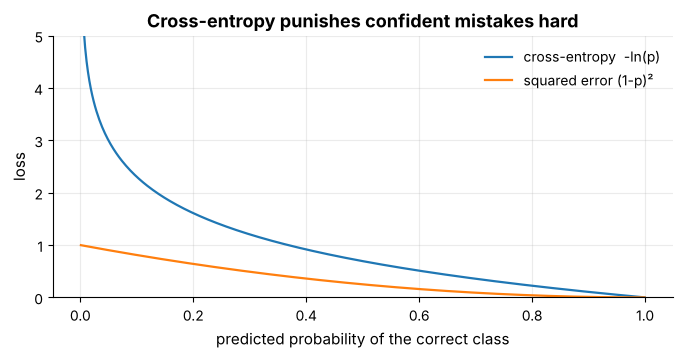

In [2]:
p = np.linspace(0.001, 0.999, 400)           # predicted probability of the TRUE class (true label = 1)
plt.figure(figsize=(8, 3.4))
plt.plot(p, -np.log(p), label="cross-entropy  -ln(p)"); plt.plot(p, (1 - p) ** 2, label="squared error (1-p)²")
plt.ylim(0, 5); plt.xlabel("predicted probability of the correct class"); plt.ylabel("loss"); plt.legend(); plt.title("Cross-entropy punishes confident mistakes hard"); plt.show()

---
### 🧩 Exercise 1: Implement losses and their gradients  ⭐⭐

With `y` the targets and `p` the predictions (NumPy arrays of equal length), write:
- `mse(y, p)` and `mse_grad(y, p)` = $\partial\mathcal L/\partial p_i = \frac{2}{n}(p_i - y_i)$
- `bce(y, p)` (binary cross-entropy; clip `p` to `[1e-12, 1-1e-12]`) and `bce_grad(y, p)` = $\frac{1}{n}\,\frac{p_i - y_i}{p_i(1-p_i)}$

<details><summary>💡 Hint 1: gentle nudge</summary>

`np.mean((y - p) ** 2)`; gradient `2 * (p - y) / len(y)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`p = np.clip(p, 1e-12, 1 - 1e-12)`; `-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`bce_grad`: `(p - y) / (p * (1 - p)) / len(y)` (clip `p` first!).

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def mse(y, p): return None
def mse_grad(y, p): return None
def bce(y, p): return None
def bce_grad(y, p): return None

In [ ]:
try:
    yy, pp = np.array([1., 0., 1., 0.]), np.array([.9, .2, .4, .6])
    def num_grad(f, p, eps=1e-6):
        g = np.zeros_like(p)
        for i in range(len(p)):
            a, b = p.copy(), p.copy(); a[i] += eps; b[i] -= eps; g[i] = (f(yy, a) - f(yy, b)) / (2 * eps)
        return g
    ag.check("mse value", np.isclose(mse(yy, pp), np.mean((yy - pp) ** 2)))
    ag.check("mse gradient matches numerical gradient", np.allclose(mse_grad(yy, pp), num_grad(mse, pp), atol=1e-6))
    ag.check("bce value", np.isclose(bce(yy, pp), -np.mean(yy*np.log(pp) + (1-yy)*np.log(1-pp))))
    ag.check("bce gradient matches numerical gradient", np.allclose(bce_grad(yy, pp), num_grad(bce, pp), atol=1e-5))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 2 · Gradient descent: walking downhill in the fog

You're on a foggy hillside and want the valley. You can't see, but you can feel the **slope** under your feet. Strategy: take a step **opposite to the slope**.

$$\theta \leftarrow \theta - \eta\,\nabla_\theta \mathcal L$$

- $\nabla_\theta\mathcal L$ = the **gradient**: the direction of steepest *increase*.
- $\eta$ = the **learning rate**: the step size. *The most important hyper-parameter you will ever tune.*

Smallest possible example: minimise $f(w)=(w-3)^2$, with gradient $f'(w)=2(w-3)$.

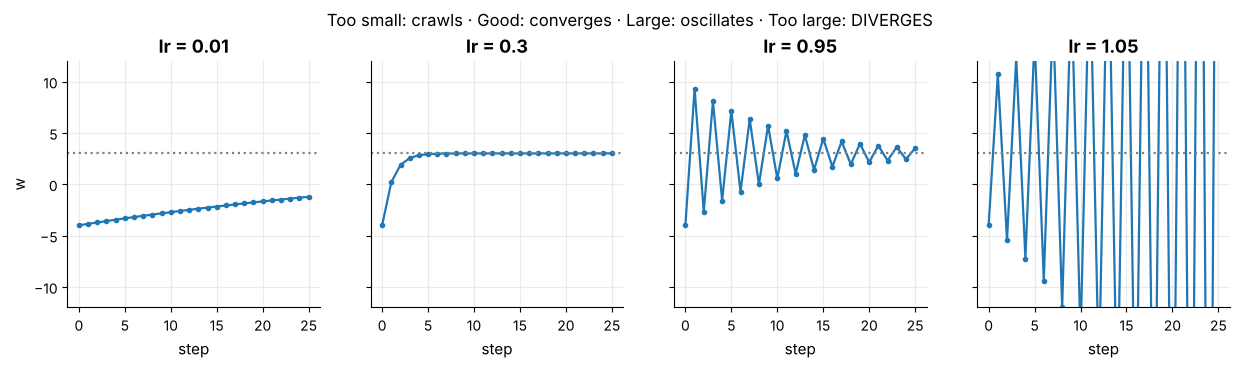

In [5]:
def descend(lr, steps=25, w0=-4.0):
    w, path = w0, [w0]
    for _ in range(steps):
        w = w - lr * 2 * (w - 3); path.append(w)
    return np.array(path)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, lr in zip(axes, [0.01, 0.3, 0.95, 1.05]):
    path = descend(lr); ax.plot(path, marker=".")
    ax.axhline(3, color="gray", ls=":"); ax.set_title(f"lr = {lr}"); ax.set_xlabel("step"); ax.set_ylim(-12, 12)
axes[0].set_ylabel("w"); plt.suptitle("Too small: crawls · Good: converges · Large: oscillates · Too large: DIVERGES", y=1.04); plt.show()

For this parabola, any $\eta<1$ converges and $\eta>1$ explodes (each step multiplies the distance to the minimum by $\lvert 1-2\eta\rvert$).
Real losses are bumpier, but the same story holds.

**Vocabulary you'll hear constantly**

| Term | Meaning |
|---|---|
| **Epoch** | one full pass through the training data |
| **Batch size** | how many samples are used to estimate one gradient |
| **Iteration (step)** | one parameter update |
| **Batch GD** | all $N$ samples per step: exact gradient, slow |
| **Stochastic GD** | 1 sample per step: noisy, fast |
| **Mini-batch GD** | e.g. 32 samples: the practical sweet spot |

With $N=1000$ and batch size $100$: **10 iterations per epoch**.

---
### 🧩 Exercise 2: Which learning rates converge?  ⭐

Run gradient descent on $f(w)=(w-3)^2$ from $w_0=-4$ for 50 steps for each learning rate in `lrs = [0.001, 0.1, 0.5, 0.9, 1.0, 1.1]`.
Store in dict `final_w` the **final** `w` for each lr (keys = lr), and in a list `diverged` the learning rates for which `|w_final - 3| > 1` after 50 steps.

<details><summary>💡 Hint 1: gentle nudge</summary>

You can reuse `descend(lr, steps=50)`; its last element is the final `w`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`final_w = {lr: descend(lr, 50)[-1] for lr in lrs}`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`diverged = [lr for lr in lrs if abs(final_w[lr] - 3) > 1]`: note lr=0.001 is *too slow* and also stays far away!

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
lrs = [0.001, 0.1, 0.5, 0.9, 1.0, 1.1]
final_w = {}
diverged = []

In [ ]:
try:
    ag.check("lr=0.1 and 0.5 reach the minimum", abs(final_w[0.1] - 3) < 1e-3 and abs(final_w[0.5] - 3) < 1e-3)
    ag.check("lr=1.1 diverges", 1.1 in diverged)
    ag.check("lr=1.0 bounces forever (never converges)", 1.0 in diverged, "step size 1.0 jumps exactly across the minimum each time")
    ag.check("lr=0.001 has barely moved after 50 steps (too slow)", 0.001 in diverged)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

### A real problem: price elasticity of demand, learned by gradient descent
Economists model how sold volume responds to price: $\ln(\text{volume}) = a + b\ln(\text{price})$. The slope $b$ is the **elasticity**.
This is linear regression (a "network" with one neuron and no activation) trained by gradient descent.

gradient descent elasticity = -1.211 | closed-form (np.polyfit) = -1.211


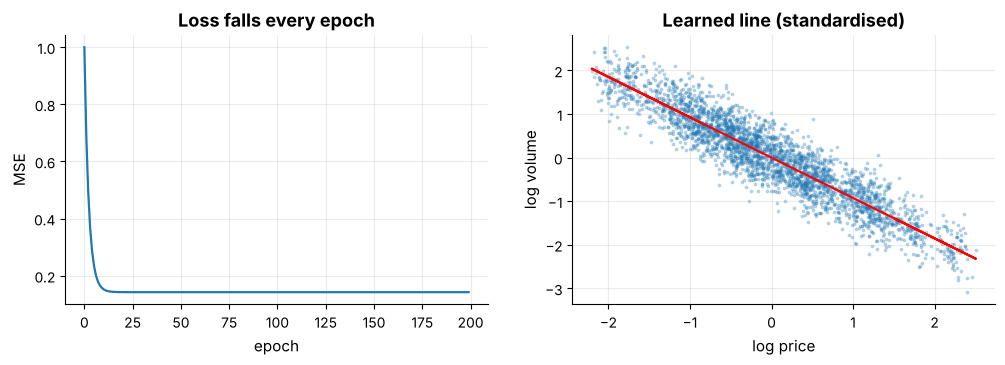

In [8]:
d = ag.load_prices("tomato", "Central")
d = d[(d.price_per_kg < 400)]                                   # drop the decimal slips
xp, yv = np.log(d.price_per_kg.to_numpy()), np.log(d.volume_tonnes.to_numpy())
xs, ys = (xp - xp.mean()) / xp.std(), (yv - yv.mean()) / yv.std()       # standardise: makes gradient descent well-behaved

a, b, lr, hist = 0.0, 0.0, 0.1, []
for epoch in range(200):
    pred = a + b * xs
    err = pred - ys
    hist.append(np.mean(err ** 2))
    a -= lr * 2 * np.mean(err)                  # dL/da
    b -= lr * 2 * np.mean(err * xs)             # dL/db
elasticity = b * yv.std() / xp.std()            # convert slope back to original log-units
print(f"gradient descent elasticity = {elasticity:.3f} | closed-form (np.polyfit) = {np.polyfit(xp, yv, 1)[0]:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(hist); axes[0].set(title="Loss falls every epoch", xlabel="epoch", ylabel="MSE")
axes[1].scatter(xs, ys, s=3, alpha=.25); axes[1].plot(xs, a + b * xs, "r"); axes[1].set(title="Learned line (standardised)", xlabel="log price", ylabel="log volume"); plt.show()

A 1 % price rise is associated with roughly a 1.2 % fall in volume: gradient descent recovered the elasticity built into the data: **learning by repeated small corrections**, no matrix inversion required.

---
## 3 · Back-propagation: the chain rule, organised

A network is a **composition of functions**: $\hat y = f_3(f_2(f_1(x)))$. The chain rule says the sensitivity of the loss to an early weight is the *product* of local sensitivities along the path.
**Back-propagation** is nothing but the chain rule applied efficiently, from the output **backward**, re-using intermediate results.

### A worked example with numbers (follow it with a pencil)
One input $x=2$, one hidden ReLU neuron, one linear output, squared loss:
$$h=\operatorname{ReLU}(w_1x+b_1),\quad \hat y = w_2h,\quad \mathcal L=(\hat y-y)^2$$
with $w_1=0.5,\; b_1=0,\; w_2=-1,\; y=1$.

**Forward:** $z=w_1x=1$ → $h=1$ → $\hat y=-1$ → $\mathcal L=(-1-1)^2=4$.

**Backward** (each line uses the line above it):
1. $\partial\mathcal L/\partial\hat y = 2(\hat y-y) = -4$
2. $\partial\mathcal L/\partial w_2 = (-4)\cdot h = -4$ and $\partial\mathcal L/\partial h = (-4)\cdot w_2 = 4$
3. ReLU gate: $\partial h/\partial z = 1$ since $z>0$, so $\partial\mathcal L/\partial z = 4$
4. $\partial\mathcal L/\partial w_1 = 4\cdot x = 8$, $\partial\mathcal L/\partial b_1 = 4$

Let's confirm with the numerical "poke it and see" method:

In [9]:
def loss_fn(w1, b1, w2, x=2.0, y=1.0):
    h = max(0.0, w1 * x + b1); return (w2 * h - y) ** 2

eps = 1e-6
for name, args, idx in [("dL/dw1", (0.5, 0.0, -1.0), 0), ("dL/db1", (0.5, 0.0, -1.0), 1), ("dL/dw2", (0.5, 0.0, -1.0), 2)]:
    hi, lo = list(args), list(args); hi[idx] += eps; lo[idx] -= eps
    print(f"{name} numerical = {(loss_fn(*hi) - loss_fn(*lo)) / (2 * eps):7.3f}")
print("analytical (by hand): dL/dw1 = 8, dL/db1 = 4, dL/dw2 = -4")

dL/dw1 numerical =   8.000
dL/db1 numerical =   4.000
dL/dw2 numerical =  -4.000
analytical (by hand): dL/dw1 = 8, dL/db1 = 4, dL/dw2 = -4


### Backward through one dense layer (the building block)
For a layer $Z = AW + \mathbf b$ (rows = samples), if we already know the upstream gradient $dZ=\partial\mathcal L/\partial Z$:

$$dW = A^\top dZ,\qquad d\mathbf b = \sum_{\text{rows}} dZ,\qquad dA = dZ\,W^\top$$

($dA$ is what we hand to the *previous* layer.) Then through a ReLU: $dZ_{\text{prev}} = dA \odot \mathbf 1[Z_{\text{prev}}>0]$.
Every deep-learning framework is, at heart, a library of these little rules plus bookkeeping.

---
### 🧩 Exercise 3: Backward pass of a dense layer  ⭐⭐

Implement `dense_backward(dZ, A_prev, W)` returning `(dW, db, dA_prev)` using the formulas above.
Shapes: `A_prev (n, n_in)`, `W (n_in, n_out)`, `dZ (n, n_out)`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`dW = A_prev.T @ dZ`: shape (n_in, n_out), same as `W`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`db = dZ.sum(axis=0)`: shape (n_out,).

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`dA_prev = dZ @ W.T`: shape (n, n_in).

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def dense_backward(dZ, A_prev, W):
    return None, None, None

In [ ]:
try:
    rng = np.random.default_rng(0)
    A_, W_, b_, T_ = rng.normal(size=(6, 4)), rng.normal(size=(4, 3)), rng.normal(size=3), rng.normal(size=(6, 3))
    L = lambda A, W, b: np.sum((A @ W + b) * T_)              # a loss whose dZ is exactly T_
    dW, db, dA = dense_backward(T_, A_, W_)
    def ng(f, X, eps=1e-6):
        g = np.zeros_like(X)
        for idx in np.ndindex(*X.shape):
            a, b2 = X.copy(), X.copy(); a[idx] += eps; b2[idx] -= eps; g[idx] = (f(a) - f(b2)) / (2 * eps)
        return g
    ag.check("dW has the right shape and values", dW is not None and dW.shape == W_.shape and np.allclose(dW, ng(lambda W: L(A_, W, b_), W_), atol=1e-5))
    ag.check("db is right", db is not None and np.allclose(db, ng(lambda b: L(A_, W_, b), b_), atol=1e-5))
    ag.check("dA_prev is right", dA is not None and np.allclose(dA, ng(lambda A: L(A, W_, b_), A_), atol=1e-5))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 4 · A complete neural network in ~40 lines of NumPy

Architecture: ReLU hidden layers, **softmax** output, **cross-entropy** loss. A neat fact: the gradient of softmax + cross-entropy w.r.t. the output pre-activation is simply
$$\frac{\partial\mathcal L}{\partial Z_{\text{out}}} = \frac{1}{n}\,(\mathbf p - \mathbf y_{\text{one-hot}})$$
- "predicted probabilities minus truth". Beautiful and cheap.

In [12]:
class MLP:
    """A tiny multi-layer perceptron: ReLU hidden layers, softmax output, cross-entropy loss."""
    def __init__(self, sizes, seed=0):
        rng = np.random.default_rng(seed)
        self.W = [rng.normal(0, np.sqrt(2 / a), (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]     # He initialisation
        self.b = [np.zeros(b) for b in sizes[1:]]

    def forward(self, X):
        self.cache, A = [X], X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            Z = A @ W + b
            if i < len(self.W) - 1:
                A = np.maximum(0, Z)                                   # ReLU
            else:
                e = np.exp(Z - Z.max(axis=1, keepdims=True)); A = e / e.sum(axis=1, keepdims=True)   # softmax
            self.cache.append(A)
        return A

    def loss(self, probs, y):
        return float(-np.mean(np.log(probs[np.arange(len(y)), y] + 1e-12)))

    def backward(self, y):
        n, L = len(y), len(self.W)
        dZ = self.cache[-1].copy(); dZ[np.arange(n), y] -= 1; dZ /= n         # softmax + cross-entropy
        gW, gb = [None] * L, [None] * L
        for i in reversed(range(L)):
            gW[i], gb[i] = self.cache[i].T @ dZ, dZ.sum(axis=0)
            if i > 0:
                dZ = (dZ @ self.W[i].T) * (self.cache[i] > 0)                  # through the previous ReLU
        return gW, gb

    def predict(self, X):
        return self.forward(X).argmax(axis=1)

X, y = make_moons(700, noise=0.25, random_state=0)
X = (X - X.mean(0)) / X.std(0)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
net = MLP([2, 16, 16, 2])
probs = net.forward(Xtr)
print(f"untrained: loss = {net.loss(probs, ytr):.3f} (chance level ln2 = 0.693), accuracy = {np.mean(net.predict(Xte) == yte):.2f}")

untrained: loss = 0.730 (chance level ln2 = 0.693), accuracy = 0.67


### Trust, but verify: numerical gradient checking
Back-prop code is notoriously easy to get subtly wrong. The professional safety net: compare analytic gradients to finite differences
$\frac{\mathcal L(w+\epsilon)-\mathcal L(w-\epsilon)}{2\epsilon}$ and look at the **relative error** (≲ 1e-6 is great, > 1e-3 means a bug).

In [13]:
def gradient_check(net, X, y, layer=0, n_checks=6, eps=1e-5, seed=0):
    probs = net.forward(X); gW, _ = net.backward(y)
    rng, errs = np.random.default_rng(seed), []
    for _ in range(n_checks):
        i, j = rng.integers(net.W[layer].shape[0]), rng.integers(net.W[layer].shape[1])
        old = net.W[layer][i, j]
        net.W[layer][i, j] = old + eps; lp = net.loss(net.forward(X), y)
        net.W[layer][i, j] = old - eps; lm = net.loss(net.forward(X), y)
        net.W[layer][i, j] = old
        num, ana = (lp - lm) / (2 * eps), gW[layer][i, j]
        errs.append(abs(num - ana) / max(1e-8, abs(num) + abs(ana)))
    return max(errs)

print("max relative error, layer 0:", f"{gradient_check(net, Xtr[:50], ytr[:50]):.2e}")

max relative error, layer 0: 3.50e-10


---
### 🧩 Exercise 4: Write the training loop  ⭐⭐⭐

Implement `fit(net, X, y, epochs=100, lr=0.1, batch_size=32, seed=0)`:
each epoch **shuffle** the sample order, then for each mini-batch call `net.forward`, `net.backward`, and update every layer:
`W[i] -= lr * gW[i]`, `b[i] -= lr * gb[i]`. Record the mean training loss per epoch (of the batches) and **return the list**.
Train a fresh `MLP([2, 16, 16, 2])` and store its test accuracy in `test_acc`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`rng = np.random.default_rng(seed)`; each epoch `order = rng.permutation(len(X))`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`for i in range(0, len(X), batch_size): idx = order[i:i+batch_size]; probs = net.forward(X[idx]); loss = net.loss(probs, y[idx]); gW, gb = net.backward(y[idx])`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Update: `for k in range(len(net.W)): net.W[k] -= lr * gW[k]; net.b[k] -= lr * gb[k]`. Then `test_acc = np.mean(net2.predict(Xte) == yte)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def fit(net, X, y, epochs=100, lr=0.1, batch_size=32, seed=0):
    losses = []
    return losses

net2 = MLP([2, 16, 16, 2], seed=1)
losses = fit(net2, Xtr, ytr)
test_acc = None

In [ ]:
try:
    ag.check("one loss per epoch (100)", len(losses) == 100)
    ag.check("the loss decreased substantially", len(losses) == 100 and losses[-1] < 0.5 * losses[0])
    ag.check("test accuracy > 0.90 on the moons", test_acc is not None and test_acc > 0.90)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

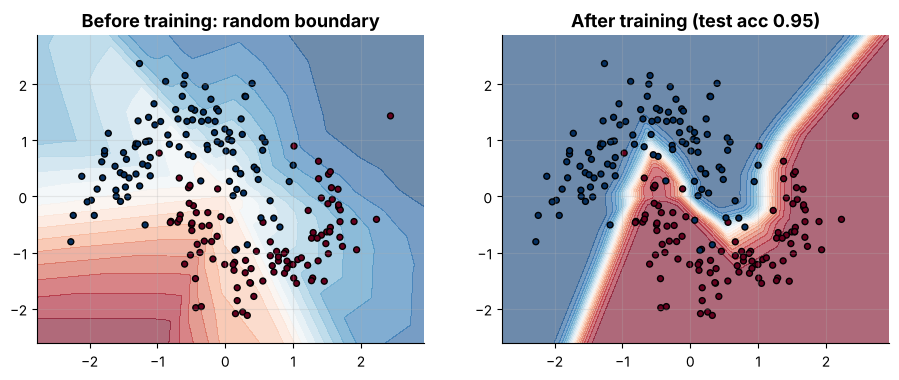

In [16]:
def plot_boundary(net, X, y, ax, title=""):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 200), np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 200))
    zz = net.forward(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap="RdBu_r", alpha=.6); ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", edgecolor="k", s=18); ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_boundary(MLP([2, 16, 16, 2]), Xte, yte, axes[0], "Before training: random boundary")
plot_boundary(net2, Xte, yte, axes[1], f"After training (test acc {test_acc:.2f})")
plt.show()

**That is deep learning.** Everything else (PyTorch, convolutions, LSTMs, Transformers) adds *new layer types with their own backward rules*, better optimisers, and engineering for speed. The core loop you just wrote does not change.

### Experiment: batch size and learning rate

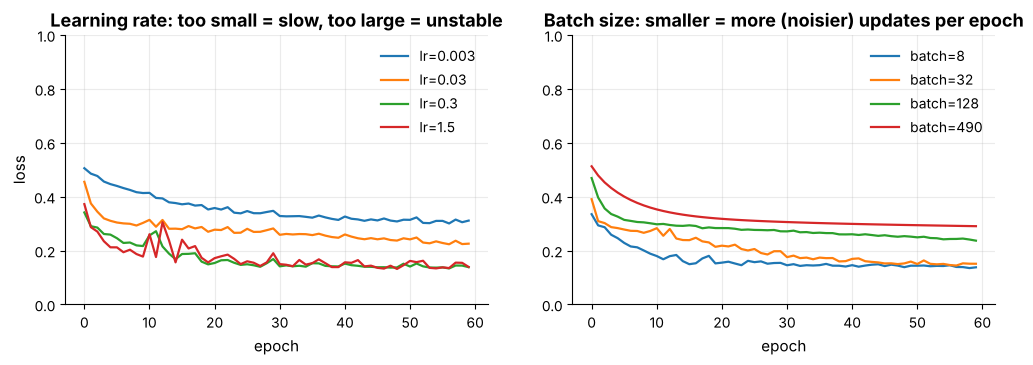

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for lr in (0.003, 0.03, 0.3, 1.5):
    n_ = MLP([2, 16, 16, 2], seed=1); axes[0].plot(fit(n_, Xtr, ytr, epochs=60, lr=lr), label=f"lr={lr}")
axes[0].set(title="Learning rate: too small = slow, too large = unstable", xlabel="epoch", ylabel="loss", ylim=(0, 1)); axes[0].legend()
for bs in (8, 32, 128, len(Xtr)):
    n_ = MLP([2, 16, 16, 2], seed=1); axes[1].plot(fit(n_, Xtr, ytr, epochs=60, lr=0.1, batch_size=bs), label=f"batch={bs}")
axes[1].set(title="Batch size: smaller = more (noisier) updates per epoch", xlabel="epoch", ylim=(0, 1)); axes[1].legend(); plt.show()

---
### 🧩 Exercise 5: Gradient check, your way  ⭐⭐

Write `numeric_grad_W(net, X, y, layer, i, j, eps=1e-5)` that returns the **central-difference** estimate of $\partial\mathcal L/\partial W_{\text{layer}}[i,j]$.
Then compare with the analytic gradient for `layer=1, i=2, j=3` of a fresh `MLP([2,16,16,2], seed=3)` on `Xtr[:40], ytr[:40]`:
store `num`, `ana` and the relative error `rel_err = |num-ana| / (|num|+|ana|)`.

<details><summary>💡 Hint 1: gentle nudge</summary>

Save the old value, set `net.W[layer][i, j] = old + eps`, compute `net.loss(net.forward(X), y)`; do the same for `old - eps`; restore the old value.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`(loss_plus - loss_minus) / (2 * eps)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Analytic: `net.forward(X); gW, gb = net.backward(y); ana = gW[1][2, 3]`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def numeric_grad_W(net, X, y, layer, i, j, eps=1e-5):
    return None

net3 = MLP([2, 16, 16, 2], seed=3)
num = ana = rel_err = None

In [ ]:
try:
    ag.check("numeric gradient is finite", num is not None and np.isfinite(num))
    ag.check("relative error < 1e-5 (back-prop is correct!)", rel_err is not None and rel_err < 1e-5,
             "restore the weight after perturbing it; use central differences")
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

## 🎓 Mini-quiz
1. You halve the batch size. What happens to the number of iterations per epoch?
2. Training loss = NaN after a few steps. Two likely causes?
3. Why does `dZ[np.arange(n), y] -= 1` implement "probabilities minus one-hot truth"?

<details><summary>Answers</summary>

1. It doubles. 2. Learning rate too high (divergence), or log(0)/overflow without clipping/stable softmax. 3. Subtracting 1 from the predicted probability of the true class turns $\mathbf p$ into $\mathbf p-\mathbf y_\text{one-hot}$ without building the one-hot matrix.
</details>

        ---
        ## 🧾 Recap
        - A **loss** turns 'how wrong' into one number; **cross-entropy** for classification, **MSE/MAE/Huber** for regression.
- **Gradient descent**: $\theta\leftarrow\theta-\eta\nabla\mathcal L$. Learning rate too small = slow, too large = divergence. Mini-batches are the practical default.
- **Forward pass** computes predictions and caches activations; **backward pass** applies the chain rule layer by layer: $dW=A^\top dZ$, $db=\sum dZ$, $dA=dZ\,W^\top$.
- Always **gradient-check** new backward code with finite differences.

**Next up:** Lesson 8.3; PyTorch: let a framework do the calculus, and meet tensors, autograd, `nn.Module`, `DataLoader` and the canonical training loop.